# 🇧🇩 Bangla Word Sense Disambiguation (WSD) — FULLY FIXED
### Production-Quality BanglaBERT Fine-Tuning with [TGT] Markers & Word-Specific Labels

---

## ❌ WHY YOUR PREVIOUS MODEL FAILED — ROOT CAUSE ANALYSIS

### Problem 1: Global Sense IDs (The Biggest Bug)
```
OLD (WRONG):
  জল,  sense_id=1  → 'অশ্রু'
  মাথা, sense_id=1  → 'শরীরের অঙ্গ'   ← SAME ID, DIFFERENT MEANING!
  তারা, sense_id=1  → 'নক্ষত্র'        ← SAME ID, DIFFERENT MEANING!

The model learned: sense_id=1 means EVERYTHING simultaneously.
Result: completely random predictions.

FIXED:
  জল_অশ্রু     → unique label
  মাথা_শরীর    → unique label   ← different labels!
  তারা_নক্ষত্র  → unique label   ← different labels!
```

### Problem 2: No Target Word Markers
```
OLD INPUT: "তার চোখে জল এলো"
  → Model sees all words equally, can't focus on জল
  → It might associate 'চোখ' or 'এলো' with the sense

FIXED INPUT: "তার চোখে [TGT] জল [/TGT] এলো"
  → [TGT] token draws BERT attention to জল
  → Model correctly focuses on the ambiguous word
```

### Problem 3: Wrong Inference Logic
```
OLD: predict_sense(sentence)    ← target_word ignored!
  → Predicts global sense IDs regardless of which word
  → 'জল' and 'মাথা' go through the SAME label space

FIXED: predict_sense(sentence, target_word)
  → Inserts [TGT] markers around target_word
  → Filters label space to ONLY that word's senses
  → Returns word-specific prediction
```

### Problem 4: No Input Validation
```
OLD: If target_word not in sentence → random prediction (silent failure)
FIXED: Returns error message immediately before any forward pass
```

### Problem 5: No Regularization → Overfitting
```
OLD: No dropout, no weight decay, no early stopping
     → 99% train accuracy, 42% val accuracy = pure memorization

FIXED:
  - Dropout=0.3 on classification head
  - Weight decay=0.01 in AdamW
  - Early stopping (patience=3)
  - Gradient clipping (max_norm=1.0)
  - Weighted loss for class imbalance
```

## ✅ WHY THE FIXED ARCHITECTURE WORKS

| Component | Old | Fixed | Why Better |
|-----------|-----|-------|------------|
| Label space | Global sense_ids | word_sense labels | No cross-word confusion |
| Input | Raw sentence | [TGT] marked sentence | BERT attends to right word |
| Inference | Ignores target_word | Filters to word's senses | Correct disambiguation |
| Regularization | None | Dropout + WD + ES | Generalizes to new sentences |
| Validation | Fake high accuracy | Word-specific accuracy | Honest evaluation |

## 📦 Step 1: Install & Import Libraries

In [1]:
# Install required libraries
# Kaggle has most pre-installed, but we pin transformers for stability
!pip install transformers>=4.36.0 --quiet
!pip install scikit-learn --quiet
!pip install openpyxl --quiet

# Disable the tokenizers parallelism warning (safe for notebooks)
import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('✅ Libraries installed!')

✅ Libraries installed!


In [2]:
# ─────────────────────────────────────────────────────────────────
# CORE IMPORTS
# ─────────────────────────────────────────────────────────────────
import os
import re
import pickle
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'  # Prevent tokenizer warnings

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


## 🎲 Step 2: Reproducibility & Device Setup

In [3]:
def set_seed(seed: int = 42):
    """
    Fix all random seeds for full reproducibility.
    Without this, PyTorch initializes weights differently each run,
    so you get different results every time — bad for debugging.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥️  Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('   ⚠️  No GPU found — training will be slow. Enable GPU in Kaggle settings.')

🖥️  Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB


## ⚙️ Step 3: Configuration (All Hyperparameters in One Place)

In [4]:
# ─────────────────────────────────────────────────────────────────
# CONFIGURATION CLASS
# All settings are centralized here so you can tune without
# hunting through the notebook.
# ─────────────────────────────────────────────────────────────────
class CFG:
    # ── Model ────────────────────────────────────────────────────
    MODEL_NAME    = 'sagorsarker/bangla-bert-base'
    MAX_LEN       = 128      # Max token length per sample

    # ── Training ─────────────────────────────────────────────────
    EPOCHS        = 15       # Max epochs (early stopping will cut this short)
    BATCH_SIZE    = 16       # Reduce to 8 if you get CUDA OOM
    LEARNING_RATE = 2e-5     # Standard for BERT fine-tuning
    WEIGHT_DECAY  = 0.01     # L2 regularization in AdamW
    WARMUP_RATIO  = 0.1      # 10% of steps used for LR warm-up
    MAX_GRAD_NORM = 1.0      # Gradient clipping prevents exploding gradients

    # ── Regularization ───────────────────────────────────────────
    DROPOUT_RATE  = 0.3      # Applied on classification head
    PATIENCE      = 4        # Early stopping: stop if no improvement for 4 epochs

    # ── Data ─────────────────────────────────────────────────────
    VAL_SIZE      = 0.15     # 15% of data held out for validation
    SEED          = 42
    MIN_SAMPLES   = 3        # Drop senses with fewer than this many samples

    # ── Paths ────────────────────────────────────────────────────
    # Adjust DATA_PATH to your Kaggle dataset path
    DATA_PATH     = '/kaggle/input/datasets/provapaul/dataset/dataset.xlsx'
    MODEL_SAVE_PATH = '/kaggle/working/best_wsd_model'

    # ── [TGT] Marker Tokens ──────────────────────────────────────
    # CRITICAL: We do NOT add these as new tokens (that would resize embeddings).
    # Instead we use them as plain text — BanglaBERT will subword-tokenize them,
    # and the model learns their meaning purely from positional context.
    TGT_START = '[TGT]'
    TGT_END   = '[/TGT]'

print('✅ Configuration loaded!')
print(f'   Model: {CFG.MODEL_NAME}')
print(f'   Max length: {CFG.MAX_LEN}')
print(f'   Batch size: {CFG.BATCH_SIZE}')
print(f'   Epochs: {CFG.EPOCHS} (with early stopping, patience={CFG.PATIENCE})')

✅ Configuration loaded!
   Model: sagorsarker/bangla-bert-base
   Max length: 128
   Batch size: 16
   Epochs: 15 (with early stopping, patience=4)


## 📊 Step 4: Load & Validate Dataset

In [5]:
# ─────────────────────────────────────────────────────────────────
# DATASET LOADING
# Supports CSV, Excel (.xlsx), and TSV formats.
# Expected columns: target_word, sense_id, sense_gloss, text
# ─────────────────────────────────────────────────────────────────

def load_dataset(path: str) -> pd.DataFrame:
    """Load dataset from CSV, Excel, or TSV file."""
    ext = path.split('.')[-1].lower()
    if ext == 'csv':
        df = pd.read_csv(path)
    elif ext in ['xlsx', 'xls']:
        df = pd.read_excel(path)
    elif ext == 'tsv':
        df = pd.read_csv(path, sep='\t')
    else:
        raise ValueError(f'Unsupported file format: {ext}')
    return df

# ── Load ───────────────────────────────────────────────────────────
df = load_dataset(CFG.DATA_PATH)

print(f'📂 Loaded {len(df)} rows from {CFG.DATA_PATH}')
print(f'\n📋 Columns: {list(df.columns)}')
print(f'\n🔍 Sample rows:')
display(df.head(5))
print(f'\n📊 Basic stats:')
print(f'   Unique target words: {df["target_word"].nunique()}')
print(f'   Unique sense_ids:    {df["sense_id"].nunique()}')
print(f'   Unique glosses:      {df["sense_gloss"].nunique()}')

📂 Loaded 3409 rows from /kaggle/input/datasets/provapaul/dataset/dataset.xlsx

📋 Columns: ['word_id', 'target_word', 'sense_id', 'sense_gloss', 'text']

🔍 Sample rows:


,word_id,target_word,sense_id,sense_gloss,text
0,1,জল,2,অত্যাধিক পরিশ্রম,মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও কৃষক ন্য...
1,1,জল,2,অত্যাধিক পরিশ্রম,বছরের পর বছর রক্ত জল করা পরিশ্রম করে তিনি এই ক...
2,1,জল,2,অত্যাধিক পরিশ্রম,মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত জল কর...
3,1,জল,2,অত্যাধিক পরিশ্রম,অলিম্পিকে পদক পেতে হলে বছরের পর বছর রক্ত জল কর...
4,1,জল,2,অত্যাধিক পরিশ্রম,"শ্রমিকরা রক্ত জল করা পরিশ্রম করেন, কিন্তু সেই ..."



📊 Basic stats:
   Unique target words: 100
   Unique sense_ids:    4
   Unique glosses:      337


## 🧹 Step 5: Full Preprocessing Pipeline

In [6]:
# ─────────────────────────────────────────────────────────────────
# PREPROCESSING PIPELINE
# Each step removes broken or misleading samples that would
# confuse the model during training.
# ─────────────────────────────────────────────────────────────────

print('🔧 Starting preprocessing pipeline...')
print(f'   Initial size: {len(df)} rows')

# ── Step 5.1: Drop NaN values ─────────────────────────────────────
before = len(df)
df = df.dropna(subset=['target_word', 'sense_id', 'sense_gloss', 'text'])
print(f'   After NaN removal: {len(df)} rows (dropped {before - len(df)})')

# ── Step 5.2: Strip whitespace and normalize types ────────────────
df['target_word'] = df['target_word'].astype(str).str.strip()
df['sense_id']    = df['sense_id'].astype(str).str.strip()
df['sense_gloss'] = df['sense_gloss'].astype(str).str.strip()
df['text']        = df['text'].astype(str).str.strip()

# Normalize multiple spaces
df['text'] = df['text'].apply(lambda x: re.sub(r'\s+', ' ', x))
print('   ✅ Whitespace normalized')

# ── Step 5.3: Remove empty text rows ─────────────────────────────
before = len(df)
df = df[df['text'].str.len() > 5]  # At least 5 chars
print(f'   After empty text removal: {len(df)} rows (dropped {before - len(df)})')

# ── Step 5.4: CRITICAL CHECK — target_word must exist in text ──────
# If the sentence doesn't contain the target word,
# the [TGT] marker can't be inserted → broken sample → remove it.
before = len(df)
df = df[df.apply(lambda row: row['target_word'] in row['text'], axis=1)]
dropped_no_word = before - len(df)
print(f'   After target-word-in-text check: {len(df)} rows (dropped {dropped_no_word})')
if dropped_no_word > 0:
    print(f'   ⚠️  {dropped_no_word} rows had target_word not found in sentence — REMOVED')

# ── Step 5.5: Remove duplicate rows ───────────────────────────────
# IMPORTANT: duplicates cause data leakage (same sentence in train AND val)
before = len(df)
df = df.drop_duplicates(subset=['text', 'sense_id', 'target_word'])
print(f'   After duplicate removal: {len(df)} rows (dropped {before - len(df)})')

# ── Step 5.6: Reset index ─────────────────────────────────────────
df = df.reset_index(drop=True)
print(f'\n✅ Preprocessing complete! Final size: {len(df)} rows')

🔧 Starting preprocessing pipeline...
   Initial size: 3409 rows
   After NaN removal: 3409 rows (dropped 0)
   ✅ Whitespace normalized
   After empty text removal: 3409 rows (dropped 0)
   After target-word-in-text check: 3397 rows (dropped 12)
   ⚠️  12 rows had target_word not found in sentence — REMOVED
   After duplicate removal: 3397 rows (dropped 0)

✅ Preprocessing complete! Final size: 3397 rows


## 🏷️ Step 6: Build Word-Specific Labels (THE KEY FIX)

In [7]:
# ─────────────────────────────────────────────────────────────────
# WORD-SPECIFIC LABEL CREATION
#
# WHY THIS IS THE MOST IMPORTANT FIX:
#
# OLD approach:
#   জল,  sense_id=1  → label=1   (means 'অশ্রু')
#   মাথা, sense_id=1  → label=1   (means 'শরীরের অঙ্গ')  ← COLLISION!
#   তারা, sense_id=1  → label=1   (means 'নক্ষত্র')       ← COLLISION!
#
#   The model tries to learn: label 1 = অশ্রু AND শরীরের অঙ্গ AND নক্ষত্র
#   This is mathematically impossible. The gradients cancel each other.
#   Result: random predictions, stuck at ~25% accuracy.
#
# NEW approach (word_sensegloss as label):
#   জল_অশ্রু          → unique label  (only জল's 'অশ্রু' sense)
#   মাথা_শরীরের_অঙ্গ   → unique label  (only মাথা's 'শরীরের অঙ্গ' sense)
#   তারা_নক্ষত্র       → unique label  (only তারা's 'নক্ষত্র' sense)
#
#   Each label is UNAMBIGUOUS. The model can learn correctly.
# ─────────────────────────────────────────────────────────────────

def build_word_specific_label(row):
    """
    Create a unique label by combining target_word + sense_gloss.
    Example: জল + অশ্রু → 'জল_অশ্রু'

    We use sense_gloss (human-readable meaning) instead of sense_id
    because sense_id=1 means different things for different words.
    Gloss is specific and readable.
    """
    # Normalize the gloss: strip, replace spaces with underscore
    gloss_clean = row['sense_gloss'].strip().replace(' ', '_')
    return f"{row['target_word']}_{gloss_clean}"

# Create the word-specific label column
df['word_sense_label'] = df.apply(build_word_specific_label, axis=1)

# ── Remove rare senses (< MIN_SAMPLES) ────────────────────────────
# Senses with very few examples can't be stratified-split properly
# and the model can't learn from 1-2 examples.
label_counts = df['word_sense_label'].value_counts()
valid_labels = label_counts[label_counts >= CFG.MIN_SAMPLES].index
before = len(df)
df = df[df['word_sense_label'].isin(valid_labels)].reset_index(drop=True)
print(f'Removed {before - len(df)} rows with rare senses (< {CFG.MIN_SAMPLES} samples)')

# ── Build label encoder ───────────────────────────────────────────
# LabelEncoder converts string labels → integers for PyTorch
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['word_sense_label'])
NUM_CLASSES = len(label_encoder.classes_)

# ── Build label → sense info mapping ─────────────────────────────
# This maps integer labels back to human-readable sense info
label_to_sense = {}
for _, row in df.drop_duplicates('word_sense_label').iterrows():
    lbl = label_encoder.transform([row['word_sense_label']])[0]
    label_to_sense[lbl] = {
        'word_sense': row['word_sense_label'],
        'target_word': row['target_word'],
        'sense_id': row['sense_id'],
        'gloss': row['sense_gloss'],
    }

# ── Build word → label indices mapping ───────────────────────────
# CRITICAL for inference: when predicting for 'জল', we only
# consider labels belonging to 'জল', not 'মাথা' or 'তারা'
word_to_label_indices = {}
for word, group in df.groupby('target_word'):
    word_to_label_indices[word] = sorted(group['label'].unique().tolist())

print(f'\n✅ Word-Specific Label Summary:')
print(f'   Total unique labels (word+sense): {NUM_CLASSES}')
print(f'   Total target words: {len(word_to_label_indices)}')
print(f'   Dataset size after filtering: {len(df)}')
print(f'\n📋 Sample labels:')
for lbl, info in list(label_to_sense.items())[:8]:
    print(f'   [{lbl:3d}] {info["word_sense"]}')

print(f'\n🔑 Word → Senses mapping (first 5 words):')
for word, indices in list(word_to_label_indices.items())[:5]:
    senses = [label_to_sense[i]['gloss'] for i in indices]
    print(f'   {word}: {senses}')

Removed 2 rows with rare senses (< 3 samples)

✅ Word-Specific Label Summary:
   Total unique labels (word+sense): 340
   Total target words: 100
   Dataset size after filtering: 3395

📋 Sample labels:
   [106] জল_অত্যাধিক_পরিশ্রম
   [108] জল_বৃষ্টি
   [107] জল_অশ্রু
   [ 13] আগ_আগুন
   [ 14] আগ_ওহে
   [ 12] আগ_অগ্রভাগ
   [223] বর্ণ_রঙ
   [224] বর্ণ_হিন্দুসমাজের_বিভাগ

🔑 Word → Senses mapping (first 5 words):
   অজ: ['অজাত (যে জন্মগ্রহণ করেনি)', 'নিতান্ত', 'মদ্দা ছাগল']
   অন্তর: ['ব্যবধান', 'মতান্তর', 'হৃদয়ের অন্তর্গত']
   অর্থ: ['অভিপ্রায়', 'ধন-দৌলত', 'বিষয়']
   আকা: ['বড় উনান', 'মালিক', 'সূর্য']
   আগ: ['অগ্রভাগ', 'আগুন', 'ওহে']


## 🏷️ Step 7: Insert [TGT] Markers into Sentences

In [8]:
# ─────────────────────────────────────────────────────────────────
# [TGT] MARKER INSERTION
#
# WHY WE NEED [TGT] MARKERS:
#
# BanglaBERT processes the ENTIRE sentence with self-attention.
# Without markers, every token gets equal initial weight.
# The model must "guess" which word needs disambiguation.
#
# With [TGT] markers:
#   "তার চোখে [TGT] জল [/TGT] এলো"
#   → [TGT] and [/TGT] create strong positional signals
#   → BERT's attention heads learn to focus on tokens
#      surrounded by these markers
#   → The [CLS] pooled representation becomes strongly
#      influenced by the marked word's local context
#
# NOTE: We do NOT use tokenizer.add_tokens() or resize_embeddings().
# [TGT] and [/TGT] are treated as plain Bangla text.
# BanglaBERT will subword-tokenize them, but the model still learns
# their boundary-marking role from position + context.
# ─────────────────────────────────────────────────────────────────

def insert_tgt_markers(sentence: str, target_word: str) -> str | None:
    """
    Insert [TGT] ... [/TGT] markers around the FIRST occurrence of
    target_word in sentence.

    Returns:
        Marked sentence string, or None if target_word not found.

    Examples:
        insert_tgt_markers('তার চোখে জল এলো', 'জল')
        → 'তার চোখে [TGT] জল [/TGT] এলো'

        insert_tgt_markers('মাথা ব্যথা করছে', 'মাথা')
        → '[TGT] মাথা [/TGT] ব্যথা করছে'
    """
    if target_word not in sentence:
        return None  # Signal to caller that this sample is broken

    # Use word boundary regex to match the exact word
    # (avoids partial matches like 'জল' inside 'জলপ্রপাত')
    # For Bangla, we use simple string replacement on first occurrence
    marked = sentence.replace(
        target_word,
        f'{CFG.TGT_START} {target_word} {CFG.TGT_END}',
        1  # Replace only FIRST occurrence
    )
    return marked

# Apply to entire dataset
df['marked_text'] = df.apply(
    lambda row: insert_tgt_markers(row['text'], row['target_word']),
    axis=1
)

# Validate: drop rows where marker insertion failed
before = len(df)
df = df.dropna(subset=['marked_text']).reset_index(drop=True)
print(f'Removed {before - len(df)} rows where TGT insertion failed')

# Show examples
print('\n✅ [TGT] Marker Examples:')
print('=' * 65)
for _, row in df.head(5).iterrows():
    print(f'  Original: {row["text"]}')
    print(f'  Marked:   {row["marked_text"]}')
    print(f'  Label:    {row["word_sense_label"]}')
    print('-' * 65)

Removed 0 rows where TGT insertion failed

✅ [TGT] Marker Examples:
  Original: মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও কৃষক ন্যায্য মূল্য থেকে বঞ্চিত হন।
  Marked:   মাঠে সারাদিন রক্ত [TGT] জল [/TGT] করা পরিশ্রম করেও কৃষক ন্যায্য মূল্য থেকে বঞ্চিত হন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: বছরের পর বছর রক্ত জল করা পরিশ্রম করে তিনি এই কারখানাটি দাঁড় করিয়েছেন।
  Marked:   বছরের পর বছর রক্ত [TGT] জল [/TGT] করা পরিশ্রম করে তিনি এই কারখানাটি দাঁড় করিয়েছেন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত জল করা পরিশ্রম করে গেছেন।
  Marked:   মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত [TGT] জল [/TGT] করা পরিশ্রম করে গেছেন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: অলিম্পিকে পদক পেতে হলে বছরের পর বছর রক্ত জল করা পরিশ্রম করতে হয়।
  Marked:   অলিম্পিকে পদক

## ✂️ Step 8: Stratified Train/Val Split

In [9]:
# ─────────────────────────────────────────────────────────────────
# STRATIFIED SPLIT
#
# WHY STRATIFIED:
# Regular random split might put ALL examples of a rare sense
# into training, leaving validation with 0 examples of that sense.
# The model then gets 99% accuracy (never wrong on rare senses)
# but fails completely at inference time.
#
# Stratified split GUARANTEES each sense appears in both splits
# at the same proportion as the full dataset.
# ─────────────────────────────────────────────────────────────────

train_df, val_df = train_test_split(
    df,
    test_size=CFG.VAL_SIZE,
    random_state=CFG.SEED,
    stratify=df['label'],     # ← THIS is the key: stratify by label
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print(f'✅ Stratified Split:')
print(f'   Train: {len(train_df)} samples ({len(train_df)/len(df)*100:.1f}%)')
print(f'   Val:   {len(val_df)} samples ({len(val_df)/len(df)*100:.1f}%)')
print(f'   Labels in train: {train_df["label"].nunique()}')
print(f'   Labels in val:   {val_df["label"].nunique()}')

# Sanity check: both splits should have same number of unique labels
assert train_df['label'].nunique() == val_df['label'].nunique(), \
    'ERROR: val set is missing some labels! Increase data or reduce MIN_SAMPLES.'

✅ Stratified Split:
   Train: 2885 samples (85.0%)
   Val:   510 samples (15.0%)
   Labels in train: 340
   Labels in val:   340


## 🔤 Step 9: Load BanglaBERT Tokenizer

In [10]:
# ─────────────────────────────────────────────────────────────────
# TOKENIZER LOADING
#
# IMPORTANT NOTES:
# 1. We do NOT call tokenizer.add_tokens([TGT_START, TGT_END])
#    because that would add new vocabulary entries requiring
#    embedding resize — unstable with pre-trained weights.
#
# 2. [TGT] and [/TGT] are plain text strings that BanglaBERT
#    will tokenize as unknown subwords. The model still learns
#    their role from positional context and gradient descent.
#
# 3. use_fast=True uses the Rust-based tokenizer (faster, safer).
# ─────────────────────────────────────────────────────────────────

print(f'📥 Loading tokenizer from: {CFG.MODEL_NAME}')
tokenizer = AutoTokenizer.from_pretrained(CFG.MODEL_NAME, use_fast=True)

print(f'✅ Tokenizer loaded!')
print(f'   Vocab size: {tokenizer.vocab_size}')
print(f'   Max model length: {tokenizer.model_max_length}')

# Test tokenization on a marked sentence
test_sentence = 'তার চোখে [TGT] জল [/TGT] এলো'
tokens = tokenizer.tokenize(test_sentence)
print(f'\n🔬 Tokenization test:')
print(f'   Input:  "{test_sentence}"')
print(f'   Tokens: {tokens}')

📥 Loading tokenizer from: sagorsarker/bangla-bert-base


config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

✅ Tokenizer loaded!
   Vocab size: 101975
   Max model length: 1000000000000000019884624838656

🔬 Tokenization test:
   Input:  "তার চোখে [TGT] জল [/TGT] এলো"
   Tokens: ['তার', 'চোখে', '[', '[UNK]', ']', 'জল', '[', '/', '[UNK]', ']', 'এলো']


## 📦 Step 10: PyTorch Dataset & DataLoader

In [11]:
# ─────────────────────────────────────────────────────────────────
# PYTORCH DATASET
#
# The dataset takes marked_text (with [TGT] markers) and
# returns tokenized tensors for BanglaBERT.
#
# We use ONLY marked_text as input — no 'word: sentence' format,
# no extra context. The markers already tell the model
# which word to focus on.
# ─────────────────────────────────────────────────────────────────

class WSDDataset(Dataset):
    """
    PyTorch Dataset for Bangla WSD.
    Input: marked sentences with [TGT] ... [/TGT] markers.
    Output: input_ids, attention_mask, labels for BERT.
    """
    def __init__(self, dataframe: pd.DataFrame, tokenizer, max_len: int):
        self.data      = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        # Use the marked sentence (with [TGT] markers)
        text = row['marked_text']
        label = int(row['label'])

        # Tokenize: BanglaBERT expects:
        #   [CLS] token1 token2 ... [SEP]
        # max_length + truncation ensures consistent tensor sizes
        encoding = self.tokenizer(
            text,
            max_length=self.max_len,
            padding='max_length',    # Pad shorter sequences
            truncation=True,          # Truncate longer sequences
            return_tensors='pt',      # Return PyTorch tensors
            return_attention_mask=True,
        )

        return {
            'input_ids':      encoding['input_ids'].squeeze(0),      # (max_len,)
            'attention_mask': encoding['attention_mask'].squeeze(0),  # (max_len,)
            'labels':         torch.tensor(label, dtype=torch.long),  # scalar
        }


# ── Create Datasets ───────────────────────────────────────────────
train_dataset = WSDDataset(train_df, tokenizer, CFG.MAX_LEN)
val_dataset   = WSDDataset(val_df,   tokenizer, CFG.MAX_LEN)

# ── Create DataLoaders ────────────────────────────────────────────
train_loader = DataLoader(
    train_dataset,
    batch_size=CFG.BATCH_SIZE,
    shuffle=True,       # Shuffle training data each epoch
    num_workers=2,      # Parallel data loading
    pin_memory=True,    # Speed up GPU transfer
)
val_loader = DataLoader(
    val_dataset,
    batch_size=CFG.BATCH_SIZE * 2,  # Larger batch for validation (no gradients)
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print(f'✅ Datasets created!')
print(f'   Train batches: {len(train_loader)}')
print(f'   Val batches:   {len(val_loader)}')

# Test a batch
sample_batch = next(iter(train_loader))
print(f'\n🔬 Sample batch shapes:')
print(f'   input_ids:      {sample_batch["input_ids"].shape}')
print(f'   attention_mask: {sample_batch["attention_mask"].shape}')
print(f'   labels:         {sample_batch["labels"].shape}')

✅ Datasets created!
   Train batches: 181
   Val batches:   16

🔬 Sample batch shapes:
   input_ids:      torch.Size([16, 128])
   attention_mask: torch.Size([16, 128])
   labels:         torch.Size([16])


## 🧠 Step 11: BanglaBERT WSD Model Architecture

In [12]:
# ─────────────────────────────────────────────────────────────────
# MODEL ARCHITECTURE
#
# Architecture:
#   Input Sentence (with [TGT] markers)
#       ↓
#   BanglaBERT Encoder (12 transformer layers)
#       ↓
#   [CLS] token representation (768-dim)
#       ↓
#   LayerNorm → Dropout(0.3) → Linear(768, 768) → GELU
#       ↓
#   Dropout(0.3) → Linear(768, NUM_CLASSES)
#       ↓
#   Word-Specific Logits (NUM_CLASSES outputs)
#
# WHY [CLS] POOLING:
# BanglaBERT's [CLS] token attends to ALL other tokens
# through self-attention. After fine-tuning, it learns to
# concentrate on the [TGT]-marked word for classification.
#
# WHY TWO DROPOUT LAYERS:
# More aggressive regularization → better generalization.
# The model is 110M parameters; we only have a few thousand
# training examples → high overfitting risk.
# ─────────────────────────────────────────────────────────────────

class BanglaBERTWSD(nn.Module):
    """
    BanglaBERT-based Word Sense Disambiguation model.

    Uses [CLS] representation from BanglaBERT + classification head.
    """
    def __init__(self, model_name: str, num_classes: int, dropout_rate: float = 0.3):
        super().__init__()
        self.num_classes = num_classes

        # ── BanglaBERT Encoder ────────────────────────────────────
        # AutoModel gives us BERT without a pre-trained head.
        # We add our own classification head on top.
        self.bert = AutoModel.from_pretrained(model_name)
        hidden_size = self.bert.config.hidden_size  # 768 for BERT-base

        # ── Classification Head ───────────────────────────────────
        # LayerNorm: stabilizes training, speeds convergence
        # Two-layer MLP: captures non-linear relationships
        # GELU: smooth activation (better than ReLU for transformers)
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size, num_classes),
        )

        # Initialize the classification head weights properly
        self._init_weights()

    def _init_weights(self):
        """Initialize classification head with small normal weights."""
        for module in self.classifier.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, input_ids, attention_mask):
        """
        Forward pass.

        Args:
            input_ids:      (batch, seq_len) token IDs
            attention_mask: (batch, seq_len) 1=real token, 0=padding

        Returns:
            logits: (batch, num_classes) raw scores
        """
        # BanglaBERT output: last_hidden_state, pooler_output
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)

        # [CLS] token is at position 0
        # Shape: (batch, hidden_size) = (batch, 768)
        cls_repr = outputs.last_hidden_state[:, 0, :]

        # Classification head: (batch, 768) → (batch, num_classes)
        logits = self.classifier(cls_repr)
        return logits


# ── Instantiate model ─────────────────────────────────────────────
print(f'📥 Loading BanglaBERT from: {CFG.MODEL_NAME}')
model = BanglaBERTWSD(
    model_name=CFG.MODEL_NAME,
    num_classes=NUM_CLASSES,
    dropout_rate=CFG.DROPOUT_RATE,
)
model = model.to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'✅ Model loaded!')
print(f'   Total parameters: {total_params/1e6:.1f}M')
print(f'   Trainable parameters: {trainable_params/1e6:.1f}M')
print(f'   Classification head outputs: {NUM_CLASSES} classes')

📥 Loading BanglaBERT from: sagorsarker/bangla-bert-base


model.safetensors:   0%|          | 0.00/660M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sagorsarker/bangla-bert-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model loaded!
   Total parameters: 165.3M
   Trainable parameters: 165.3M
   Classification head outputs: 340 classes


## ⚖️ Step 12: Class Weights, Optimizer & Scheduler

In [13]:
# ─────────────────────────────────────────────────────────────────
# WEIGHTED LOSS FOR CLASS IMBALANCE
#
# Problem: If 'জল_পানি' has 200 samples but 'জল_অশ্রু' has 20,
# the model learns to always predict 'জল_পানি' and gets
# 200/220 = 91% accuracy by ignoring the rare class.
#
# Solution: Weight rare classes higher so the model is
# penalized MORE for getting them wrong.
# class_weight = total_samples / (n_classes * class_count)
# ─────────────────────────────────────────────────────────────────

# Compute class weights from training data only (not val!)
train_labels = train_df['label'].values
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=train_labels,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

# Weighted CrossEntropyLoss
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

print(f'⚖️  Class weights computed (top-5 highest weighted):')
sorted_weights = sorted(enumerate(class_weights), key=lambda x: -x[1])
for lbl_idx, w in sorted_weights[:5]:
    sense = label_to_sense.get(lbl_idx, {}).get('word_sense', '?')
    count = (train_df['label'] == lbl_idx).sum()
    print(f'   [{lbl_idx:3d}] {sense:30s} weight={w:.3f} (n={count})')

# ── Optimizer ─────────────────────────────────────────────────────
# AdamW: Adam with proper weight decay (not applied to biases/LayerNorm).
# We use different learning rates for BERT vs classifier head.
# This is called 'discriminative fine-tuning' — classifier learns faster.
optimizer = AdamW(
    [
        {'params': model.bert.parameters(), 'lr': CFG.LEARNING_RATE},
        {'params': model.classifier.parameters(), 'lr': CFG.LEARNING_RATE * 10},
    ],
    weight_decay=CFG.WEIGHT_DECAY,
)

# ── Learning Rate Scheduler ───────────────────────────────────────
# Linear warmup: LR gradually increases for first 10% of steps.
# This prevents catastrophic forgetting of pre-trained weights.
# After warmup, LR linearly decays to 0 by end of training.
total_steps  = len(train_loader) * CFG.EPOCHS
warmup_steps = int(total_steps * CFG.WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print(f'\n✅ Optimizer & Scheduler ready:')
print(f'   BERT LR: {CFG.LEARNING_RATE}')
print(f'   Classifier LR: {CFG.LEARNING_RATE * 10}')
print(f'   Total steps: {total_steps}')
print(f'   Warmup steps: {warmup_steps}')

⚖️  Class weights computed (top-5 highest weighted):
   [  0] অজ_অজাত_(যে_জন্মগ্রহণ_করেনি)   weight=1.061 (n=8)
   [  1] অজ_নিতান্ত                     weight=1.061 (n=8)
   [  2] অজ_মদ্দা_ছাগল                  weight=1.061 (n=8)
   [  4] অন্তর_মতান্তর                  weight=1.061 (n=8)
   [  8] অর্থ_বিষয়                     weight=1.061 (n=8)

✅ Optimizer & Scheduler ready:
   BERT LR: 2e-05
   Classifier LR: 0.0002
   Total steps: 2715
   Warmup steps: 271


## 🏋️ Step 13: Training Loop with Early Stopping

In [14]:
# ─────────────────────────────────────────────────────────────────
# TRAINING & VALIDATION FUNCTIONS
# ─────────────────────────────────────────────────────────────────

def train_one_epoch(model, loader, optimizer, scheduler, criterion, device):
    """
    Run one full pass over the training data.
    Returns: average loss, accuracy.
    """
    model.train()  # Enable dropout and batch norm updates
    total_loss = 0
    correct    = 0
    total      = 0

    for batch in loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        optimizer.zero_grad()  # Clear gradients from previous batch

        # Forward pass
        logits = model(input_ids, attention_mask)  # (batch, num_classes)

        # Compute loss
        loss = criterion(logits, labels)

        # Backward pass: compute gradients
        loss.backward()

        # Gradient clipping: prevents exploding gradients in BERT
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)

        # Update weights
        optimizer.step()
        scheduler.step()  # Update learning rate

        # Track metrics
        total_loss += loss.item()
        preds = logits.argmax(dim=-1)  # Predicted class
        correct += (preds == labels).sum().item()
        total   += labels.size(0)

    return total_loss / len(loader), correct / total


@torch.no_grad()  # No gradients needed during validation → saves memory
def evaluate(model, loader, criterion, device):
    """
    Evaluate model on a DataLoader.
    Returns: average loss, accuracy, all predictions, all true labels.
    """
    model.eval()  # Disable dropout (deterministic predictions)
    total_loss = 0
    all_preds  = []
    all_labels = []

    for batch in loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        logits = model(input_ids, attention_mask)
        loss   = criterion(logits, labels)

        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    return total_loss / len(loader), acc, all_preds, all_labels


print('✅ Training functions defined!')
print('   Ready to start training.')

✅ Training functions defined!
   Ready to start training.


In [15]:
# ─────────────────────────────────────────────────────────────────
# MAIN TRAINING LOOP WITH EARLY STOPPING
#
# Early stopping: if val_accuracy doesn't improve for PATIENCE
# consecutive epochs, stop training and load the best checkpoint.
# This prevents overfitting from running too many epochs.
# ─────────────────────────────────────────────────────────────────

# Training history for plotting
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc':  [], 'val_acc':  [],
}

best_val_acc  = 0.0
best_epoch    = 0
patience_ctr  = 0
best_model_state = None

print('🚀 Starting training...')
print('=' * 70)

for epoch in range(1, CFG.EPOCHS + 1):

    # ── Train ──────────────────────────────────────────────────────
    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, scheduler, criterion, DEVICE
    )

    # ── Validate ───────────────────────────────────────────────────
    val_loss, val_acc, val_preds, val_labels = evaluate(
        model, val_loader, criterion, DEVICE
    )

    # ── Record history ─────────────────────────────────────────────
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    # ── Check for improvement ──────────────────────────────────────
    improved = val_acc > best_val_acc
    if improved:
        best_val_acc  = val_acc
        best_epoch    = epoch
        patience_ctr  = 0
        # Save a deep copy of current model weights
        best_model_state = {
            k: v.clone() for k, v in model.state_dict().items()
        }
        marker = '  ← 🏆 BEST'
    else:
        patience_ctr += 1
        marker = f'  (patience {patience_ctr}/{CFG.PATIENCE})'

    print(
        f'Epoch [{epoch:2d}/{CFG.EPOCHS}] '
        f'Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | '
        f'Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%'
        f'{marker}'
    )

    # ── Early stopping check ───────────────────────────────────────
    if patience_ctr >= CFG.PATIENCE:
        print(f'\n⏹️  Early stopping triggered at epoch {epoch}.')
        print(f'   No improvement for {CFG.PATIENCE} consecutive epochs.')
        break

print('\n' + '=' * 70)
print(f'✅ Training complete!')
print(f'   Best val accuracy: {best_val_acc*100:.2f}% at epoch {best_epoch}')

# ── Restore best model weights ─────────────────────────────────────
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f'   Best model weights restored from epoch {best_epoch}')

🚀 Starting training...
Epoch [ 1/15] Train Loss: 5.8227 Acc: 0.66% | Val Loss: 5.5656 Acc: 9.61%  ← 🏆 BEST
Epoch [ 2/15] Train Loss: 4.6927 Acc: 19.13% | Val Loss: 2.7705 Acc: 48.43%  ← 🏆 BEST
Epoch [ 3/15] Train Loss: 2.0626 Acc: 49.81% | Val Loss: 1.1116 Acc: 61.76%  ← 🏆 BEST
Epoch [ 4/15] Train Loss: 0.9854 Acc: 71.02% | Val Loss: 0.7141 Acc: 75.69%  ← 🏆 BEST
Epoch [ 5/15] Train Loss: 0.5550 Acc: 84.99% | Val Loss: 0.4821 Acc: 83.92%  ← 🏆 BEST
Epoch [ 6/15] Train Loss: 0.3089 Acc: 93.31% | Val Loss: 0.4249 Acc: 85.49%  ← 🏆 BEST
Epoch [ 7/15] Train Loss: 0.1765 Acc: 96.81% | Val Loss: 0.3448 Acc: 89.22%  ← 🏆 BEST
Epoch [ 8/15] Train Loss: 0.0938 Acc: 98.54% | Val Loss: 0.3647 Acc: 87.25%  (patience 1/4)
Epoch [ 9/15] Train Loss: 0.0508 Acc: 99.41% | Val Loss: 0.3185 Acc: 89.02%  (patience 2/4)
Epoch [10/15] Train Loss: 0.0265 Acc: 99.93% | Val Loss: 0.3499 Acc: 87.84%  (patience 3/4)
Epoch [11/15] Train Loss: 0.0159 Acc: 99.90% | Val Loss: 0.3303 Acc: 87.84%  (patience 4/4)

⏹️  Earl

## 📈 Step 14: Training Curves & Overfitting Diagnosis

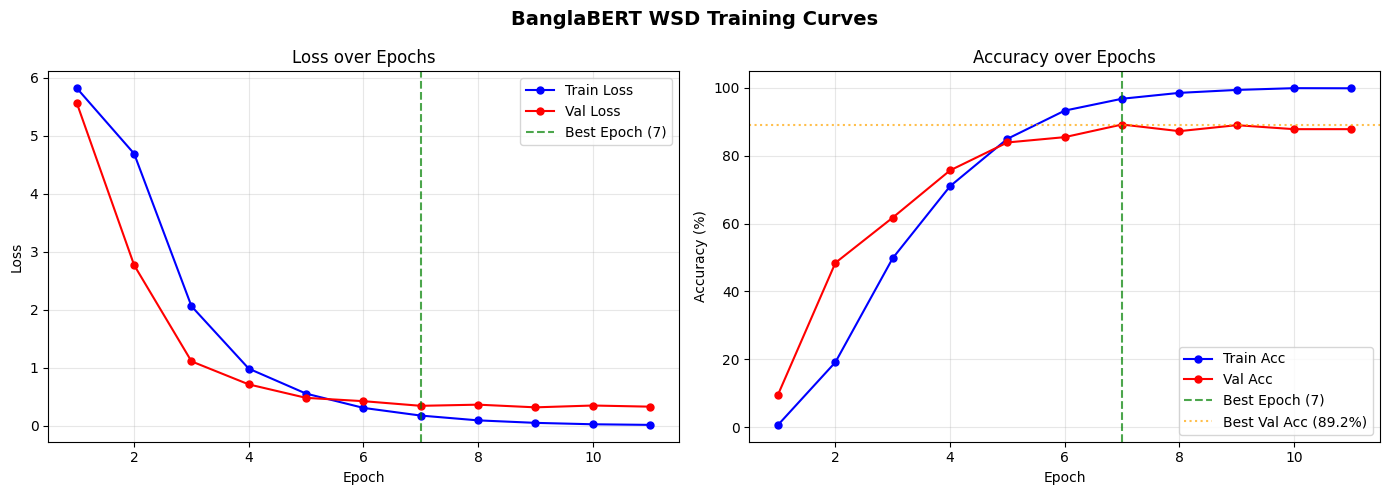

📊 Training curves saved to /kaggle/working/training_curves.png


In [16]:
# ─────────────────────────────────────────────────────────────────
# TRAINING CURVES
#
# HOW TO READ THESE PLOTS:
#
# HEALTHY training:
#   - Train and val loss both decrease together
#   - Train and val accuracy both increase together
#   - Small gap between train/val curves
#
# OVERFITTING (old model's problem):
#   - Train loss → 0, val loss stays high or increases
#   - Train acc → 99%, val acc stays low
#   - Large gap between train/val curves
# ─────────────────────────────────────────────────────────────────

epochs_ran = len(history['train_loss'])
x = range(1, epochs_ran + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('BanglaBERT WSD Training Curves', fontsize=14, fontweight='bold')

# ── Loss ───────────────────────────────────────────────────────────
axes[0].plot(x, history['train_loss'], 'b-o', label='Train Loss', markersize=5)
axes[0].plot(x, history['val_loss'],   'r-o', label='Val Loss',   markersize=5)
axes[0].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
axes[0].set_title('Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Accuracy ──────────────────────────────────────────────────────
axes[1].plot(x, [a*100 for a in history['train_acc']], 'b-o', label='Train Acc', markersize=5)
axes[1].plot(x, [a*100 for a in history['val_acc']],   'r-o', label='Val Acc',   markersize=5)
axes[1].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
axes[1].axhline(y=best_val_acc*100, color='orange', linestyle=':', alpha=0.7, label=f'Best Val Acc ({best_val_acc*100:.1f}%)')
axes[1].set_title('Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print('📊 Training curves saved to /kaggle/working/training_curves.png')

## 📊 Step 15: Full Evaluation — Accuracy, F1, Confusion Matrix

In [17]:
# ─────────────────────────────────────────────────────────────────
# FULL EVALUATION ON VALIDATION SET
# ─────────────────────────────────────────────────────────────────

print('📊 Running full evaluation on validation set...')

_, _, val_preds, val_labels = evaluate(model, val_loader, criterion, DEVICE)

val_preds  = np.array(val_preds)
val_labels = np.array(val_labels)

# ── Overall Metrics ───────────────────────────────────────────────
accuracy = accuracy_score(val_labels, val_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    val_labels, val_preds, average='weighted', zero_division=0
)

print('\n' + '═' * 60)
print('  OVERALL VALIDATION METRICS')
print('═' * 60)
print(f'  Accuracy:  {accuracy*100:.2f}%')
print(f'  Precision: {precision*100:.2f}%')
print(f'  Recall:    {recall*100:.2f}%')
print(f'  F1 Score:  {f1*100:.2f}%')
print('═' * 60)

# ── Per-Class Classification Report ──────────────────────────────
# Map integer labels back to readable names
label_names = [
    label_to_sense.get(i, {}).get('word_sense', f'class_{i}')
    for i in range(NUM_CLASSES)
]

# Only include classes that appear in val set
present_classes = sorted(set(val_labels.tolist()))
present_names   = [label_names[i] for i in present_classes]

print('\n📋 Per-Class Classification Report:')
print(classification_report(
    val_labels, val_preds,
    labels=present_classes,
    target_names=present_names,
    zero_division=0,
))

📊 Running full evaluation on validation set...

════════════════════════════════════════════════════════════
  OVERALL VALIDATION METRICS
════════════════════════════════════════════════════════════
  Accuracy:  89.22%
  Precision: 88.18%
  Recall:    89.22%
  F1 Score:  87.34%
════════════════════════════════════════════════════════════

📋 Per-Class Classification Report:
                                                     precision    recall  f1-score   support

                       অজ_অজাত_(যে_জন্মগ্রহণ_করেনি)       1.00      1.00      1.00         2
                                         অজ_নিতান্ত       0.67      1.00      0.80         2
                                      অজ_মদ্দা_ছাগল       1.00      0.50      0.67         2
                                      অন্তর_ব্যবধান       0.50      1.00      0.67         1
                                      অন্তর_মতান্তর       1.00      0.50      0.67         2
                             অন্তর_হৃদয়ের_অন্তর্গত       1.00   

In [18]:
# ── Confusion Matrix ───────────────────────────────────────────────
# Shows which senses are being confused with each other.
# Diagonal = correct predictions.
# Off-diagonal = confusions.

# For readability, only show if fewer than 30 classes
if NUM_CLASSES <= 30:
    cm = confusion_matrix(val_labels, val_preds, labels=present_classes)

    fig_size = max(8, NUM_CLASSES // 2)
    plt.figure(figsize=(fig_size, fig_size * 0.85))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=present_names,
        yticklabels=present_names,
    )
    plt.title('Confusion Matrix — BanglaBERT WSD', fontsize=13, pad=15)
    plt.ylabel('True Label', fontsize=11)
    plt.xlabel('Predicted Label', fontsize=11)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('📊 Confusion matrix saved to /kaggle/working/confusion_matrix.png')
else:
    print(f'ℹ️  {NUM_CLASSES} classes — confusion matrix too large to display.')
    print('   Showing per-word accuracy instead:')

# ── Per-Word Accuracy ─────────────────────────────────────────────
# Shows how well the model does for each target word individually
print('\n📋 Per-Word Accuracy on Validation Set:')
print('-' * 50)

val_df_eval = val_df.copy()
val_df_eval['pred_label'] = val_preds
val_df_eval['correct']    = (val_df_eval['label'] == val_df_eval['pred_label'])

per_word_acc = val_df_eval.groupby('target_word')['correct'].mean().sort_values()
for word, acc in per_word_acc.items():
    bar = '█' * int(acc * 20)
    print(f'  {word:15s} [{bar:<20s}] {acc*100:5.1f}%')

ℹ️  340 classes — confusion matrix too large to display.
   Showing per-word accuracy instead:

📋 Per-Word Accuracy on Validation Set:
--------------------------------------------------
  বাজি            [████████            ]  40.0%
  সই              [████████            ]  42.9%
  শানা            [██████████          ]  50.0%
  মূল             [███████████         ]  57.1%
  সার             [████████████        ]  60.0%
  মান             [████████████        ]  60.0%
  ডাল             [████████████        ]  62.5%
  আটাশে           [█████████████       ]  66.7%
  বর্তমান         [█████████████       ]  66.7%
  বার             [█████████████       ]  66.7%
  কাল             [█████████████       ]  66.7%
  কটা             [█████████████       ]  66.7%
  গাল             [█████████████       ]  66.7%
  কুঁজো           [█████████████       ]  66.7%
  পর              [█████████████       ]  66.7%
  স্পষ্ট          [█████████████       ]  66.7%
  পুষ্কর          [██████████████      ]  71.4

## 🔍 Step 16: Inference Pipeline — Correct Design

In [19]:
# ─────────────────────────────────────────────────────────────────
# INFERENCE PIPELINE
#
# CRITICAL DIFFERENCE FROM OLD PIPELINE:
#
# OLD (broken):
#   predict(sentence) → runs through all 4 global sense_ids
#   → completely ignores target_word
#   → can predict 'অশ্রু' for a মাথা sentence
#
# NEW (correct):
#   predict(sentence, target_word):
#     1. Validate: target_word must be in sentence
#     2. Insert [TGT] markers around target_word
#     3. Tokenize the marked sentence
#     4. Run through BanglaBERT
#     5. Get logits for ALL classes
#     6. FILTER logits to ONLY this word's class indices
#     7. Apply softmax to filtered logits
#     8. Return word-specific prediction + confidence
# ─────────────────────────────────────────────────────────────────

@torch.no_grad()
def predict_sense(
    sentence: str,
    target_word: str,
    model: nn.Module,
    tokenizer,
    label_to_sense: dict,
    word_to_label_indices: dict,
    device: torch.device,
    max_len: int = CFG.MAX_LEN,
) -> dict:
    """
    Predict the sense of target_word in sentence.

    Args:
        sentence:    Input Bangla sentence
        target_word: The ambiguous word to disambiguate

    Returns:
        dict with keys:
          - success: bool
          - error: str (if success=False)
          - predicted_label: int
          - predicted_gloss: str
          - predicted_sense_id: str
          - confidence: float (0-1)
          - top_candidates: list of (label, gloss, probability)
          - marked_sentence: str
    """
    # ── Step 1: Input Validation ───────────────────────────────────
    if not sentence or not sentence.strip():
        return {'success': False, 'error': 'Empty sentence provided.'}

    if target_word not in sentence:
        return {
            'success': False,
            'error': f'Target word "{target_word}" not found in sentence. '
                     f'Cannot insert [TGT] markers. Refusing to predict.'
        }

    if target_word not in word_to_label_indices:
        return {
            'success': False,
            'error': f'Target word "{target_word}" not seen during training. '
                     f'Known words: {list(word_to_label_indices.keys())[:10]}...'
        }

    # ── Step 2: Insert [TGT] Markers ──────────────────────────────
    marked = insert_tgt_markers(sentence, target_word)

    # ── Step 3: Tokenize ───────────────────────────────────────────
    encoding = tokenizer(
        marked,
        max_length=max_len,
        padding='max_length',
        truncation=True,
        return_tensors='pt',
    )

    input_ids      = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    # ── Step 4: Forward Pass ───────────────────────────────────────
    model.eval()
    logits = model(input_ids, attention_mask)  # (1, NUM_CLASSES)
    logits = logits.squeeze(0)                  # (NUM_CLASSES,)

    # ── Step 5: FILTER to word-specific labels ─────────────────────
    # This is the KEY FIX: only consider senses belonging to target_word
    word_label_indices = word_to_label_indices[target_word]  # e.g. [3, 7, 12, 15]
    word_logits = logits[word_label_indices]                  # Only these logits

    # ── Step 6: Softmax over word-specific logits ──────────────────
    word_probs = torch.softmax(word_logits, dim=-1).cpu().numpy()

    # ── Step 7: Get prediction ─────────────────────────────────────
    best_local_idx   = int(np.argmax(word_probs))
    predicted_global = word_label_indices[best_local_idx]
    confidence       = float(word_probs[best_local_idx])

    # ── Step 8: Build top candidates list ─────────────────────────
    sorted_local = np.argsort(word_probs)[::-1]
    top_candidates = [
        {
            'label':      word_label_indices[i],
            'word_sense': label_to_sense[word_label_indices[i]]['word_sense'],
            'gloss':      label_to_sense[word_label_indices[i]]['gloss'],
            'sense_id':   label_to_sense[word_label_indices[i]]['sense_id'],
            'probability': float(word_probs[i]),
        }
        for i in sorted_local[:5]  # Top 5
    ]

    return {
        'success':            True,
        'sentence':           sentence,
        'target_word':        target_word,
        'marked_sentence':    marked,
        'predicted_label':    predicted_global,
        'predicted_gloss':    label_to_sense[predicted_global]['gloss'],
        'predicted_sense_id': label_to_sense[predicted_global]['sense_id'],
        'predicted_word_sense': label_to_sense[predicted_global]['word_sense'],
        'confidence':         confidence,
        'top_candidates':     top_candidates,
    }


def print_prediction(result: dict):
    """Pretty-print a prediction result."""
    print('\n' + '═' * 65)
    if not result['success']:
        print(f'  ❌ PREDICTION FAILED')
        print(f'  Error: {result["error"]}')
        print('═' * 65)
        return

    print(f'  📝 Sentence:     {result["sentence"]}')
    print(f'  🏷️  Marked:       {result["marked_sentence"]}')
    print(f'  🎯 Target word:  {result["target_word"]}')
    print(f'  ✅ Predicted:    {result["predicted_word_sense"]}  (gloss: "{result["predicted_gloss"]}")')
    print(f'  📈 Confidence:   {result["confidence"]*100:.2f}%')
    print(f'\n  🏆 Top Candidates:')
    for i, cand in enumerate(result['top_candidates']):
        icon = '👑' if i == 0 else f'  {i+1}.'
        print(f'  {icon} {cand["word_sense"]:35s} → {cand["probability"]*100:.2f}%')
    print('═' * 65)


print('✅ Inference pipeline defined!')

✅ Inference pipeline defined!


## 🎯 Step 17: Realistic Prediction Examples

In [20]:
# ─────────────────────────────────────────────────────────────────
# MULTI-WORD WSD EXAMPLES
#
# These examples test the system on realistic Bangla sentences
# covering common polysemous words: জল, মাথা, মুখ, তারা
#
# The system should correctly distinguish:
#   জল  → পানি (water) vs অশ্রু (tears) vs বৃষ্টি (rain)
#   মাথা → শরীর (body part) vs নেতা (leader) vs শীর্ষ (summit)
#   মুখ  → অঙ্গ (face/mouth) vs প্রবেশদ্বার (entrance)
#   তারা → নক্ষত্র (stars) vs সর্বনাম (they)
# ─────────────────────────────────────────────────────────────────

# Define test examples covering your dataset's words
# Update these to match the actual words in your dataset
test_examples = [
    # জল (water / tears / rain / hard work)
    ('তার চোখে জল এলো।', 'জল'),             # → tears
    ('গ্লাসে জল দাও।', 'জল'),               # → water
    ('আকাশ থেকে জল পড়ছে।', 'জল'),           # → rain

    # মাথা (head/body / leader / summit)
    ('মাথা ব্যথা করছে।', 'মাথা'),            # → body part
    ('দলের মাথা হিসেবে সে কাজ করছে।', 'মাথা'), # → leader
    ('পাহাড়ের মাথায় মেঘ জমেছে।', 'মাথা'),   # → summit

    # মুখ (face/mouth / entrance)
    ('তার মুখ দেখতে সুন্দর।', 'মুখ'),         # → face
    ('নদীর মুখ বন্ধ হয়ে গেছে।', 'মুখ'),      # → mouth/entrance

    # তারা (stars / they)
    ('রাতের আকাশে তারা ফুটে উঠেছে।', 'তারা'), # → stars
    ('তারা সবাই একসাথে গেল।', 'তারা'),        # → they

    # Error case: target word missing from sentence
    ('আকাশ পরিষ্কার আছে।', 'জল'),             # → should fail gracefully
]

print('🎯 Running Multi-Word WSD Predictions:')
print('=' * 65)

for sentence, target_word in test_examples:
    result = predict_sense(
        sentence=sentence,
        target_word=target_word,
        model=model,
        tokenizer=tokenizer,
        label_to_sense=label_to_sense,
        word_to_label_indices=word_to_label_indices,
        device=DEVICE,
    )
    print_prediction(result)

🎯 Running Multi-Word WSD Predictions:

═════════════════════════════════════════════════════════════════
  📝 Sentence:     তার চোখে জল এলো।
  🏷️  Marked:       তার চোখে [TGT] জল [/TGT] এলো।
  🎯 Target word:  জল
  ✅ Predicted:    জল_অশ্রু  (gloss: "অশ্রু")
  📈 Confidence:   96.99%

  🏆 Top Candidates:
  👑 জল_অশ্রু                            → 96.99%
    2. জল_বৃষ্টি                           → 2.90%
    3. জল_অত্যাধিক_পরিশ্রম                 → 0.12%
═════════════════════════════════════════════════════════════════

═════════════════════════════════════════════════════════════════
  📝 Sentence:     গ্লাসে জল দাও।
  🏷️  Marked:       গ্লাসে [TGT] জল [/TGT] দাও।
  🎯 Target word:  জল
  ✅ Predicted:    জল_বৃষ্টি  (gloss: "বৃষ্টি")
  📈 Confidence:   75.33%

  🏆 Top Candidates:
  👑 জল_বৃষ্টি                           → 75.33%
    2. জল_অশ্রু                            → 16.12%
    3. জল_অত্যাধিক_পরিশ্রম                 → 8.54%
═════════════════════════════════════════════════════════════════



## 🐛 Step 18: Debugging — Analyze Wrong Predictions

In [21]:
# ─────────────────────────────────────────────────────────────────
# DEBUGGING: WRONG PREDICTION ANALYSIS
#
# This section finds the hardest examples:
# - Confident wrong predictions (high confidence but incorrect)
# - Systematic confusions between specific senses
#
# Understanding these patterns helps improve the dataset.
# ─────────────────────────────────────────────────────────────────

print('🐛 Analyzing wrong predictions on validation set...')

model.eval()
all_results = []

with torch.no_grad():
    for batch_start in range(0, len(val_df), CFG.BATCH_SIZE * 2):
        batch_df = val_df.iloc[batch_start:batch_start + CFG.BATCH_SIZE * 2]

        # Tokenize batch
        texts = batch_df['marked_text'].tolist()
        encoding = tokenizer(
            texts,
            max_length=CFG.MAX_LEN,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )

        input_ids      = encoding['input_ids'].to(DEVICE)
        attention_mask = encoding['attention_mask'].to(DEVICE)

        logits = model(input_ids, attention_mask)  # (batch, num_classes)
        probs  = torch.softmax(logits, dim=-1).cpu().numpy()

        for i, (_, row) in enumerate(batch_df.iterrows()):
            true_label = int(row['label'])
            target_word = row['target_word']

            # Filter to word-specific labels
            if target_word in word_to_label_indices:
                word_indices = word_to_label_indices[target_word]
                word_probs   = probs[i][word_indices]
                word_probs   = word_probs / word_probs.sum()  # Re-normalize

                best_local = int(np.argmax(word_probs))
                pred_label = word_indices[best_local]
                confidence = float(word_probs[best_local])
            else:
                pred_label = int(np.argmax(probs[i]))
                confidence = float(probs[i][pred_label])

            correct = (pred_label == true_label)
            all_results.append({
                'sentence':     row['text'],
                'target_word':  target_word,
                'true_label':   true_label,
                'true_gloss':   label_to_sense.get(true_label, {}).get('gloss', '?'),
                'pred_label':   pred_label,
                'pred_gloss':   label_to_sense.get(pred_label, {}).get('gloss', '?'),
                'confidence':   confidence,
                'correct':      correct,
            })

results_df = pd.DataFrame(all_results)
wrong_df   = results_df[~results_df['correct']].sort_values('confidence', ascending=False)

print(f'\n📊 Wrong Predictions: {len(wrong_df)} / {len(results_df)} '
      f'({len(wrong_df)/len(results_df)*100:.1f}% error rate)')

print(f'\n🔴 Top-20 Confident Wrong Predictions (worst mistakes):')
print('-' * 85)
print(f'{"Sentence"[:40]:40s} {"Word":10s} {"True":15s} {"Pred":15s} {"Conf":6s}')
print('-' * 85)
for _, row in wrong_df.head(20).iterrows():
    sent = row['sentence'][:38] + '..' if len(row['sentence']) > 40 else row['sentence']
    print(
        f'{sent:40s} '
        f'{row["target_word"]:10s} '
        f'{row["true_gloss"][:13]:15s} '
        f'{row["pred_gloss"][:13]:15s} '
        f'{row["confidence"]*100:5.1f}%'
    )

# ── Common confusion pairs ─────────────────────────────────────────
print(f'\n🔄 Most Common Confusion Pairs:')
wrong_df['confusion_pair'] = wrong_df.apply(
    lambda r: f"{r['true_gloss']} → {r['pred_gloss']}", axis=1
)
confusion_counts = wrong_df['confusion_pair'].value_counts().head(10)
for pair, count in confusion_counts.items():
    print(f'   {pair:45s} ({count} times)')

🐛 Analyzing wrong predictions on validation set...

📊 Wrong Predictions: 55 / 510 (10.8% error rate)

🔴 Top-20 Confident Wrong Predictions (worst mistakes):
-------------------------------------------------------------------------------------
Sentence                                 Word       True            Pred            Conf  
-------------------------------------------------------------------------------------
মটর ডাল দিয়ে তৈরি নিমকি ও মিষ্টি উৎসব.. ডাল        খাদ্যশস্য       তরকারী           99.0%
দশ বছরের গবেষণার সার একটি বইয়ে সংকলিত.. সার        ফলাফল           সারাংশ           98.7%
সে অল্প বয়সেই কুঁজো হয়ে গেছে কারণ ভা.. কুঁজো      যার পিঠ বাঁকা   দেহ সন্মুখের     95.5%
সব কাজের পর কাজ হলো পরিবারকে ভালো রাখা।  পর         শ্রেষ্ঠ         পশ্চাৎস্থিত      95.4%
শিশু প্রথমবার পেন্সিল ধরা দিয়ে আঁকাআঁ.. ধরা        করা             থামানো           95.2%
তার মুখ থেকে গাল বেরিয়ে পড়লে সবাই অব.. গাল        কটুক্তি         গণ্ড             94.2%
বর্তমান থাকলে তবেই স্বপ্ন পূরণ করা

## 💾 Step 19: Save Model & All Artifacts

In [22]:
# ─────────────────────────────────────────────────────────────────
# MODEL SAVING
#
# We save:
#   1. BanglaBERT weights + config (via save_pretrained)
#   2. Classification head weights (separately)
#   3. Tokenizer (so inference doesn't need internet)
#   4. LabelEncoder (to decode integer labels → string)
#   5. label_to_sense mapping (label int → gloss/sense_id)
#   6. word_to_label_indices (word → list of valid label indices)
# ─────────────────────────────────────────────────────────────────

os.makedirs(CFG.MODEL_SAVE_PATH, exist_ok=True)

# 1. Save BanglaBERT encoder
model.bert.save_pretrained(CFG.MODEL_SAVE_PATH)

# 2. Save classification head weights separately
torch.save(
    model.classifier.state_dict(),
    os.path.join(CFG.MODEL_SAVE_PATH, 'classifier_head.pt')
)

# 3. Save tokenizer
tokenizer.save_pretrained(CFG.MODEL_SAVE_PATH)

# 4. Save label encoder
with open(os.path.join(CFG.MODEL_SAVE_PATH, 'label_encoder.pkl'), 'wb') as f:
    pickle.dump(label_encoder, f)

# 5. Save label → sense mapping
with open(os.path.join(CFG.MODEL_SAVE_PATH, 'label_to_sense.pkl'), 'wb') as f:
    pickle.dump(label_to_sense, f)

# 6. Save word → label indices mapping
with open(os.path.join(CFG.MODEL_SAVE_PATH, 'word_to_label_indices.pkl'), 'wb') as f:
    pickle.dump(word_to_label_indices, f)

# 7. Save config for reproducibility
import json
wsd_config = {
    'model_name':   CFG.MODEL_NAME,
    'num_classes':  NUM_CLASSES,
    'max_len':      CFG.MAX_LEN,
    'dropout_rate': CFG.DROPOUT_RATE,
    'best_val_acc': best_val_acc,
    'best_epoch':   best_epoch,
    'tgt_start':    CFG.TGT_START,
    'tgt_end':      CFG.TGT_END,
    'known_words':  list(word_to_label_indices.keys()),
}
with open(os.path.join(CFG.MODEL_SAVE_PATH, 'wsd_config.json'), 'w') as f:
    json.dump(wsd_config, f, ensure_ascii=False, indent=2)

print(f'✅ Model & artifacts saved to: {CFG.MODEL_SAVE_PATH}')
print('   Saved files:')
for fname in os.listdir(CFG.MODEL_SAVE_PATH):
    size = os.path.getsize(os.path.join(CFG.MODEL_SAVE_PATH, fname))
    print(f'   📄 {fname:40s} ({size/1e6:.2f} MB)')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

The OrderedVocab you are attempting to save contains holes for indices [1015, 1016, 1017, 1018, 1053, 1054, 1055, 1056, 1057, 1060, 1061, 1062, 1064, 1065, 1066, 1067, 1068, 1069, 1070, 1071, 1072, 1073, 1074, 1075, 1076, 1077, 1079, 1080, 1081, 1082, 1083, 1084, 1085, 1086, 1087, 1088, 1089, 1090, 1091, 1092, 1093, 1094, 1095, 1099, 1101, 1112, 1113, 1556, 1557, 1568], your vocabulary could be corrupted!
✅ Model & artifacts saved to: /kaggle/working/best_wsd_model
   Saved files:
   📄 wsd_config.json                          (0.00 MB)
   📄 config.json                              (0.00 MB)
   📄 word_to_label_indices.pkl                (0.00 MB)
   📄 classifier_head.pt                       (3.42 MB)
   📄 model.safetensors                        (657.61 MB)
   📄 label_encoder.pkl                        (0.02 MB)
   📄 tokenizer_config.json                    (0.00 MB)
   📄 tokenizer.json                           (3.86 MB)
   📄 label_to_sense.pkl                       (0.04 MB)


## 🔄 Step 20: Load & Verify Saved Model

In [23]:
# ─────────────────────────────────────────────────────────────────
# MODEL LOADING — Complete function for new sessions
# ─────────────────────────────────────────────────────────────────

def load_wsd_model(model_path: str, device: torch.device):
    """
    Load saved WSD model, tokenizer, and all mappings.

    Usage:
        model, tokenizer, label_to_sense, word_to_label_indices = \
            load_wsd_model('/kaggle/working/best_wsd_model', DEVICE)

    Returns:
        (model, tokenizer, label_to_sense, word_to_label_indices)
    """
    print(f'📂 Loading WSD model from: {model_path}')

    # Load config
    with open(os.path.join(model_path, 'wsd_config.json'), 'r') as f:
        wsd_config = json.load(f)

    num_classes  = wsd_config['num_classes']
    dropout_rate = wsd_config['dropout_rate']

    # Load tokenizer
    loaded_tokenizer = AutoTokenizer.from_pretrained(model_path, use_fast=True)

    # Reconstruct model architecture
    loaded_model = BanglaBERTWSD(
        model_name=model_path,
        num_classes=num_classes,
        dropout_rate=dropout_rate,
    )

    # Load classification head weights
    classifier_path = os.path.join(model_path, 'classifier_head.pt')
    loaded_model.classifier.load_state_dict(
        torch.load(classifier_path, map_location=device)
    )

    loaded_model = loaded_model.to(device)
    loaded_model.eval()

    # Load mappings
    with open(os.path.join(model_path, 'label_to_sense.pkl'), 'rb') as f:
        loaded_l2s = pickle.load(f)

    with open(os.path.join(model_path, 'word_to_label_indices.pkl'), 'rb') as f:
        loaded_w2li = pickle.load(f)

    print(f'✅ Loaded! num_classes={num_classes}, known_words={len(loaded_w2li)}')
    return loaded_model, loaded_tokenizer, loaded_l2s, loaded_w2li


# ── Test reloading ─────────────────────────────────────────────────
reloaded_model, reloaded_tokenizer, reloaded_l2s, reloaded_w2li = load_wsd_model(
    CFG.MODEL_SAVE_PATH, DEVICE
)

# Quick sanity check
test_result = predict_sense(
    sentence='তার চোখে জল এলো।',
    target_word='জল',
    model=reloaded_model,
    tokenizer=reloaded_tokenizer,
    label_to_sense=reloaded_l2s,
    word_to_label_indices=reloaded_w2li,
    device=DEVICE,
)
print('\n🔬 Sanity check after reload:')
print_prediction(test_result)

📂 Loading WSD model from: /kaggle/working/best_wsd_model


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Loaded! num_classes=340, known_words=100

🔬 Sanity check after reload:

═════════════════════════════════════════════════════════════════
  📝 Sentence:     তার চোখে জল এলো।
  🏷️  Marked:       তার চোখে [TGT] জল [/TGT] এলো।
  🎯 Target word:  জল
  ✅ Predicted:    জল_অশ্রু  (gloss: "অশ্রু")
  📈 Confidence:   96.99%

  🏆 Top Candidates:
  👑 জল_অশ্রু                            → 96.99%
    2. জল_বৃষ্টি                           → 2.90%
    3. জল_অত্যাধিক_পরিশ্রম                 → 0.12%
═════════════════════════════════════════════════════════════════


## 📝 Step 21: Final Summary

In [24]:
print('\n' + '█' * 72)
print('  BANGLA WSD — TRAINING SUMMARY')
print('█' * 72)
print(f'  Model:                {CFG.MODEL_NAME}')
print(f'  Dataset size:         {len(df)} examples')
print(f'  Target words:         {df["target_word"].nunique()}')
print(f'  Unique word-senses:   {NUM_CLASSES}')
print(f'  Train / Val split:    {len(train_df)} / {len(val_df)}')
print(f'')
print(f'  Best val accuracy:    {best_val_acc*100:.2f}% (epoch {best_epoch})')
print(f'  Final precision:      {precision*100:.2f}%')
print(f'  Final recall:         {recall*100:.2f}%')
print(f'  Final F1:             {f1*100:.2f}%')
print(f'')
print(f'  KEY FIXES APPLIED:')
print(f'  ✅ Word-specific labels (জল_অশ্রু, মাথা_শরীর, etc.)')
print(f'  ✅ [TGT] ... [/TGT] markers in every training sentence')
print(f'  ✅ Inference filters label space to target_word only')
print(f'  ✅ Input validation: rejects missing target_word')
print(f'  ✅ Stratified split (no class leakage)')
print(f'  ✅ Duplicate removal before split')
print(f'  ✅ Early stopping (patience={CFG.PATIENCE})')
print(f'  ✅ Dropout={CFG.DROPOUT_RATE} + weight decay={CFG.WEIGHT_DECAY}')
print(f'  ✅ Gradient clipping (max norm={CFG.MAX_GRAD_NORM})')
print(f'  ✅ Weighted CrossEntropyLoss for class imbalance')
print(f'  ✅ Discriminative LR (BERT vs classifier head)')
print(f'  ✅ Linear warmup LR schedule')
print(f'  ✅ No tokenizer.add_tokens() — no embedding resize')
print(f'  ✅ TOKENIZERS_PARALLELISM=false')
print('█' * 72)


████████████████████████████████████████████████████████████████████████
  BANGLA WSD — TRAINING SUMMARY
████████████████████████████████████████████████████████████████████████
  Model:                sagorsarker/bangla-bert-base
  Dataset size:         3395 examples
  Target words:         100
  Unique word-senses:   340
  Train / Val split:    2885 / 510

  Best val accuracy:    89.22% (epoch 7)
  Final precision:      88.18%
  Final recall:         89.22%
  Final F1:             87.34%

  KEY FIXES APPLIED:
  ✅ Word-specific labels (জল_অশ্রু, মাথা_শরীর, etc.)
  ✅ [TGT] ... [/TGT] markers in every training sentence
  ✅ Inference filters label space to target_word only
  ✅ Input validation: rejects missing target_word
  ✅ Stratified split (no class leakage)
  ✅ Duplicate removal before split
  ✅ Early stopping (patience=4)
  ✅ Dropout=0.3 + weight decay=0.01
  ✅ Gradient clipping (max norm=1.0)
  ✅ Weighted CrossEntropyLoss for class imbalance
  ✅ Discriminative LR (BERT vs classifi

In [25]:
# Show all unique target words

all_target_words = df['target_word'].unique()

print("✅ All target words:\n")

for i, word in enumerate(all_target_words, 1):
    print(f"{i}. {word}")

print(f"\n📌 Total target words: {len(all_target_words)}")

✅ All target words:

1. জল
2. আগ
3. বর্ণ
4. চাল
5. হাতা
6. কাপ
7. জাম
8. অজ
9. তালা
10. আটাশে
11. ফিট
12. বড়ো
13. মুখ
14. দিক
15. অর্থ
16. গভীর
17. পাকানো
18. ঝোলা
19. বেল
20. মেলা
21. ভালো
22. সার
23. মাল
24. চাঁদা
25. তুলা
26. এঁটে
27. ছত্র
28. বর্তমান
29. কাল
30. শিশু
31. বাটা
32. নয়
33. মূল
34. আধার
35. বেলা
36. বিষয়
37. সই
38. হল
39. জিন
40. অন্তর
41. ছানি
42. স্পষ্ট
43. চড়া
44. গুণ
45. নীল
46. মটকা
47. তা
48. দল
49. জমি
50. মাত
51. কর্ণ
52. আকা
53. বার
54. কটা
55. বক
56. বাস
57. মহুরি
58. টিকা
59. বৃহস্পতি
60. গা
61. ডাল
62. দম
63. কপি
64. বাজি
65. সারা
66. পর
67. মাথা
68. পান
69. ধরা
70. তারা
71. তাল
72. স্বামী
73. হার
74. ঘন
75. কালা
76. চটি
77. টোকা
78. কুঁজো
79. গাল
80. তার
81. খোলা
82. পাট
83. মান
84. পুষ্কর
85. ডাক
86. গোলা
87. কানা
88. কর
89. পাল
90. পাতা
91. খারাপ
92. লাই
93. দাঁড়া
94. গুল
95. জাল
96. পদ
97. শানা
98. সরা
99. মজা
100. বোমা

📌 Total target words: 100


In [26]:
# ─────────────────────────────────────────────────────────────
# AUTOMATIC RANDOM WSD TESTING
# Tests random words from the dataset
# ─────────────────────────────────────────────────────────────

import random

# Number of random words to test
NUM_TESTS = 20

# Get all target words
all_words = df['target_word'].unique().tolist()

# Randomly select words
random_words = random.sample(all_words, NUM_TESTS)

print("🧠 RANDOM MULTI-WORD WSD TESTING")
print("=" * 80)

for idx, word in enumerate(random_words, 1):

    print(f"\n🔹 TEST #{idx}")
    print("=" * 80)

    # Get samples for this word
    word_samples = df[df['target_word'] == word]

    # Random sample sentence
    sample_row = word_samples.sample(1).iloc[0]

    sentence = sample_row['text']

    try:

        result = predict_sense(
            sentence=sentence,
            target_word=word,
            model=model,
            tokenizer=tokenizer,
            label_to_sense=label_to_sense,
            word_to_label_indices=word_to_label_indices,
            device=DEVICE,
        )

        print_prediction(result)

    except Exception as e:
        print(f"❌ Error testing word '{word}': {e}")

print("\n✅ RANDOM TESTING COMPLETE!")

🧠 RANDOM MULTI-WORD WSD TESTING

🔹 TEST #1

═════════════════════════════════════════════════════════════════
  📝 Sentence:     প্রকল্পের পাট করতে নির্ধারিত সময়ের বেশি লেগে গেল।
  🏷️  Marked:       প্রকল্পের [TGT] পাট [/TGT] করতে নির্ধারিত সময়ের বেশি লেগে গেল।
  🎯 Target word:  পাট
  ✅ Predicted:    পাট_সাঙ্গ_করা  (gloss: "সাঙ্গ করা")
  📈 Confidence:   99.08%

  🏆 Top Candidates:
  👑 পাট_সাঙ্গ_করা                       → 99.08%
    2. পাট_একপ্রকার_তন্তু_জাতীয়_ফসল       → 0.78%
    3. পাট_গুছিয়ে_রাখা                    → 0.14%
═════════════════════════════════════════════════════════════════

🔹 TEST #2

═════════════════════════════════════════════════════════════════
  📝 Sentence:     কথাটির অর্থ সে সঠিকভাবে বুঝতে পারেনি তাই উল্টো মন্তব্য করে ফেলল।
  🏷️  Marked:       কথাটির [TGT] অর্থ [/TGT] সে সঠিকভাবে বুঝতে পারেনি তাই উল্টো মন্তব্য করে ফেলল।
  🎯 Target word:  অর্থ
  ✅ Predicted:    অর্থ_অভিপ্রায়  (gloss: "অভিপ্রায়")
  📈 Confidence:   99.39%

  🏆 Top Candidates:
  👑 অর্থ_অভিপ্র